# Week 2: Does turnover depend on the weekday?

**Question:** On which weekdays does the bakery sell more or less – for all products together and for each
product group – and are the differences larger than chance?

**How:** we add up the turnover of each day, average it per weekday (Monday to Sunday) and show the
average with a 95 % confidence interval. Data: `umsatzdaten_gekuerzt.csv` (01.07.2013 – 31.07.2018),
loaded from the course repository given in `AGENTS.md`.

**Step 1 – Load the tools.** *pandas* handles tables, *scipy* provides the t-distribution for the
confidence interval, *matplotlib* draws the charts.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

**Step 2 – Load the sales data and check it.** Each row is the turnover (`Umsatz`) of one product group
(`Warengruppe`) on one date (`Datum`). The `assert` lines stop the notebook if the data is not what the
dataset documentation promises: 9,334 rows and exactly one row per date and product group.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])

assert len(sales) == 9334, "Unexpected number of rows"
assert not sales.duplicated(subset=["Datum", "Warengruppe"]).any(), "A date/product group appears twice"
print("Rows:", len(sales), "| Period:", sales["Datum"].min().date(), "to", sales["Datum"].max().date())

Rows: 9334 | Period: 2013-07-01 to 2018-07-31


**Step 3 – Readable names.** We replace the product group numbers 1–6 by their names and add the weekday.
The weekday is stored as an *ordered category*, so tables and charts always run **Monday to Sunday**,
not alphabetically.

In [3]:
PRODUCT_GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissants", 4: "Confectionery", 5: "Cakes", 6: "Seasonal bread"}
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


def weekday_of(dates):
    """Weekday name of each date, ordered Monday to Sunday."""
    return pd.Categorical(dates.dt.dayofweek.map(dict(enumerate(WEEKDAYS))), categories=WEEKDAYS, ordered=True)


sales["product_group"] = sales["Warengruppe"].map(PRODUCT_GROUPS)
sales["weekday"] = weekday_of(sales["Datum"])
assert sales["product_group"].notna().all()

**Step 4 – Add up the turnover per day.** We sum the turnover of all product groups for each date. The check
makes sure nothing was lost or counted twice. Days without any sales (mostly public holidays) have no rows
in the file; they are **left out, not counted as zero**, so the averages describe days on which the bakery
sold something.

In [4]:
daily_total = sales.groupby("Datum", as_index=False)["Umsatz"].sum().rename(columns={"Umsatz": "turnover"})
daily_total["weekday"] = weekday_of(daily_total["Datum"])

assert np.isclose(daily_total["turnover"].sum(), sales["Umsatz"].sum())
calendar_days = len(pd.date_range(sales["Datum"].min(), sales["Datum"].max()))
print("Days with sales:", len(daily_total), "| Days without any sales:", calendar_days - len(daily_total))

Days with sales: 1819 | Days without any sales: 38


**Step 5 – Average per weekday with a 95 % confidence interval.** For each weekday we compute the mean daily
turnover, the number of days *n*, and the interval *mean ± t × standard error* (standard error = standard
deviation / √n). If the intervals of two weekdays do not overlap, the difference is very unlikely to be
chance. For the product groups each row already is one day of one group, so we average the rows directly;
a group is only averaged over the days on which it was sold (Seasonal bread: October–January only).

In [5]:
def mean_with_ci(values, level=0.95):
    """Mean, number of days and t-based confidence interval of daily turnovers."""
    n = values.count()
    mean = values.mean()
    half_width = stats.t.ppf((1 + level) / 2, df=n - 1) * values.std(ddof=1) / np.sqrt(n)
    return pd.Series({"n": n, "mean": mean, "ci_low": mean - half_width, "ci_high": mean + half_width})


def summarise(table, by):
    summary = table.groupby(by, observed=True)["turnover"].apply(mean_with_ci).unstack()
    return summary.astype({"n": int})


summary_total = summarise(daily_total, "weekday")
summary_group = summarise(sales.rename(columns={"Umsatz": "turnover"}), ["product_group", "weekday"])
summary_total.round(1)

,n,mean,ci_low,ci_high
weekday,,,,
Monday,258,994.0,959.3,1028.7
Tuesday,262,964.8,935.5,994.2
Wednesday,263,956.6,924.4,988.9
Thursday,259,995.3,962.5,1028.0
Friday,256,1007.8,978.1,1037.6
Saturday,261,1235.3,1198.1,1272.4
Sunday,260,1272.3,1244.3,1300.3


The same table per product group:

In [6]:
summary_group.round(1)

n   mean  ci_low  ci_high
product_group  weekday                               
Bread          Monday     258  133.1   129.0    137.3
               Tuesday    262  118.5   115.1    121.8
               Wednesday  263  116.7   112.9    120.5
               Thursday   259  135.6   130.8    140.5
               Friday     256  127.8   123.8    131.8
               Saturday   261  147.9   142.3    153.5
               Sunday     260   75.6    72.6     78.6
Cakes          Monday     258  253.9   245.7    262.1
               Tuesday    262  259.7   247.8    271.7
               Wednesday  263  264.7   250.9    278.5
               Thursday   259  265.7   251.7    279.7
               Friday     256  270.1   263.0    277.3
               Saturday   261  312.1   298.1    326.1
               Sunday     260  311.2   299.6    322.9
Confectionery  Monday     251   82.3    78.9     85.8
               Tuesday    253   78.3    75.7     80.9
               Wednesday  250   77.1    74.5     79.7
               Thursday   254   76.9    73.6     80.2
               Friday     247   79.9    76.8     83.0
               Saturday   252   86.3    82.6     89.9
               Sunday     259  133.5   127.5    139.4
Croissants     Monday     258  150.3   141.4    159.1
               Tuesday    262  145.2   137.0    153.4
               Wednesday  263  143.6   135.2    151.9
               Thursday   259  143.8   135.7    152.0
               Friday     256  150.9   142.1    159.6
               Saturday   261  201.5   191.2    211.8
               Sunday     260  208.0   200.2    215.9
Rolls          Monday     258  366.3   349.9    382.8
               Tuesday    262  354.6   340.7    368.5
               Wednesday  263  348.9   335.0    362.7
               Thursday   259  363.1   348.8    377.3
               Friday     256  371.0   356.1    386.0
               Saturday   261  478.9   461.6    496.2
               Sunday     260  534.4   521.1    547.8
Seasonal bread Monday      41   64.2    54.6     73.8
               Tuesday     44   67.1    56.3     77.8
               Wednesday   40   62.9    54.7     71.1
               Thursday    44   68.5    57.5     79.5
               Friday      40   69.6    59.9     79.3
               Saturday    40   75.7    63.1     88.3
               Sunday      43   60.8    52.5     69.0

**Step 6 – Chart style.** One function draws the bars for any table from step 5, so both charts look the same:
bars start at 0, and the black error bars show the 95 % confidence interval.

In [7]:
BAR_COLOR, TEXT, TEXT_SECONDARY, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_SECONDARY, "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY, "axes.titlecolor": TEXT, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})


def weekday_bars(ax, summary, title):
    """Bars of the mean per weekday with 95 % confidence intervals as error bars."""
    summary = summary.reindex(WEEKDAYS)
    err = [summary["mean"] - summary["ci_low"], summary["ci_high"] - summary["mean"]]
    ax.bar(range(7), summary["mean"], width=0.7, color=BAR_COLOR, zorder=2)
    ax.errorbar(range(7), summary["mean"], yerr=err, fmt="none", ecolor=TEXT, elinewidth=1.2, capsize=3, zorder=3)
    ax.set_xticks(range(7), [d[:3] for d in WEEKDAYS])
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    ax.tick_params(length=0)

**Step 7 – Chart for all product groups together.**

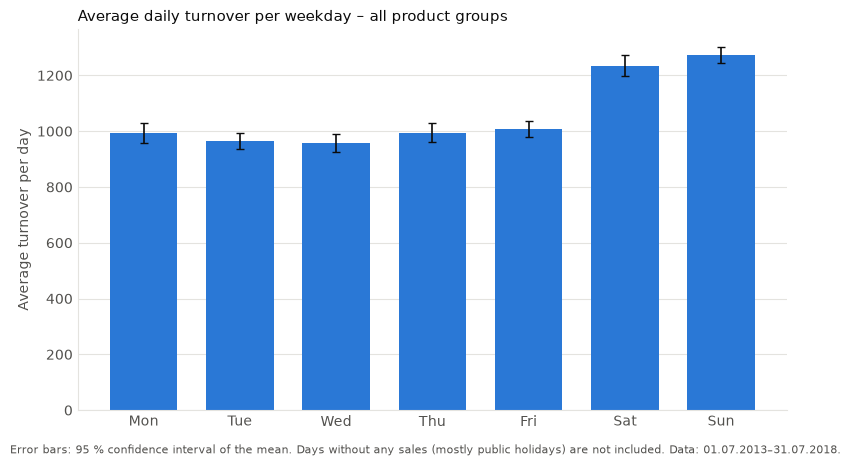

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
weekday_bars(ax, summary_total, "Average daily turnover per weekday – all product groups")
ax.set_ylabel("Average turnover per day")
fig.text(0.01, -0.02, "Error bars: 95 % confidence interval of the mean. Days without any sales "
         "(mostly public holidays) are not included. Data: 01.07.2013–31.07.2018.",
         fontsize=8, color=TEXT_SECONDARY)
fig.tight_layout()
plt.show()

**Step 8 – One chart per product group.** The groups sell very different amounts, so each subplot has its
**own y-axis**. Compare the *shape over the week* between groups; read the values from each subplot's axis.

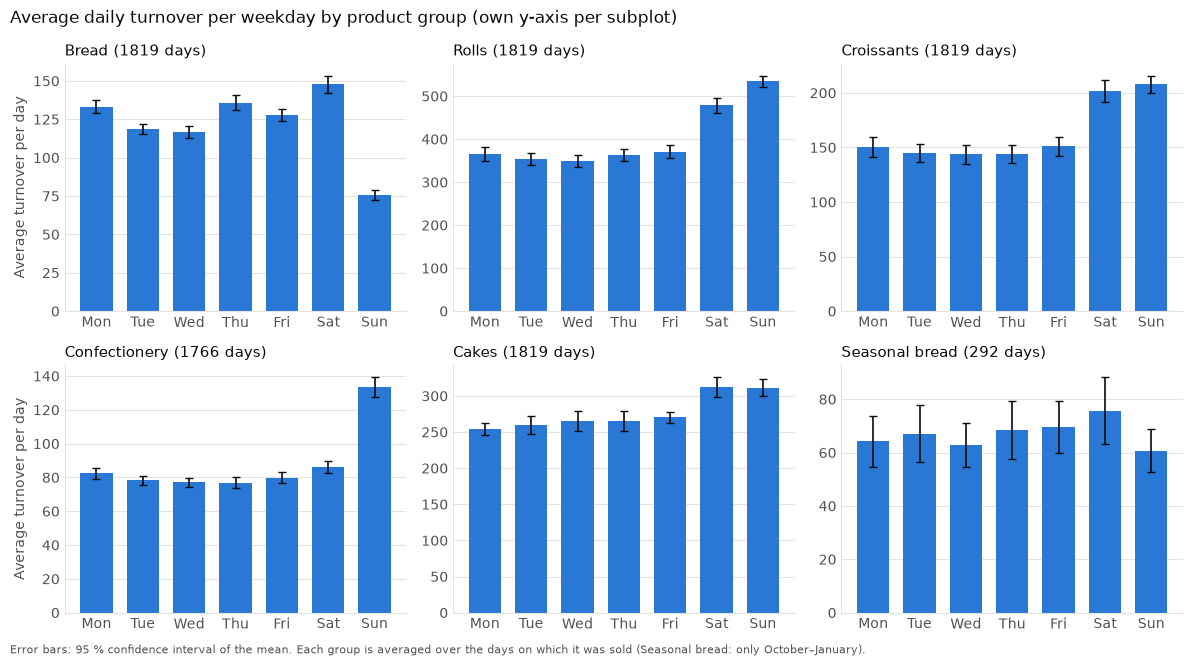

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, name in zip(axes.flat, PRODUCT_GROUPS.values()):
    weekday_bars(ax, summary_group.loc[name], f"{name} ({summary_group.loc[name, 'n'].sum()} days)")
for ax in axes[:, 0]:
    ax.set_ylabel("Average turnover per day")
fig.suptitle("Average daily turnover per weekday by product group (own y-axis per subplot)",
             x=0.01, ha="left", fontsize=12, color=TEXT)
fig.text(0.01, -0.01, "Error bars: 95 % confidence interval of the mean. Each group is averaged over the "
         "days on which it was sold (Seasonal bread: only October–January).",
         fontsize=8, color=TEXT_SECONDARY)
fig.tight_layout()
plt.show()

**Step 9 – Weekend compared with a normal weekday (for the memo).** The turnover has no currency, so we
compare instead: Saturday and Sunday turnover divided by the average Monday–Friday turnover. 1.0 means
"like a normal weekday", 1.5 means "half as much again". The 95 % range comes from *bootstrapping*: we
redraw the days at random 2,000 times and see how much the ratio moves.

We also count in how many weeks Saturday and Sunday each sold more than the average weekday of the same
week – a plain-language way to say how reliable the weekend effect is.

In [10]:
rng = np.random.default_rng(seed=42)
is_weekday = lambda t: t["weekday"].isin(WEEKDAYS[:5])


def weekend_ratio(table, n_boot=2000):
    """Saturday and Sunday mean turnover divided by the Monday–Friday mean, with a bootstrap 95 % range."""
    base = table.loc[is_weekday(table), "turnover"].to_numpy()
    rows = []
    for day in ["Saturday", "Sunday"]:
        vals = table.loc[table["weekday"] == day, "turnover"].to_numpy()
        boot = [rng.choice(vals, len(vals)).mean() / rng.choice(base, len(base)).mean() for _ in range(n_boot)]
        rows.append({"day": day, "ratio": vals.mean() / base.mean(),
                     "low": np.percentile(boot, 2.5), "high": np.percentile(boot, 97.5)})
    return pd.DataFrame(rows)


group_rows = sales.rename(columns={"Umsatz": "turnover"})
ratios = pd.concat(
    [weekend_ratio(daily_total).assign(product_group="All products")]
    + [weekend_ratio(group_rows[group_rows["product_group"] == g]).assign(product_group=g)
       for g in PRODUCT_GROUPS.values()]
)
weekend_all = daily_total.loc[~is_weekday(daily_total), "turnover"].mean() / daily_total.loc[is_weekday(daily_total), "turnover"].mean()
print(f"Weekend day vs. average weekday (all products): {weekend_all:.2f}")
ratios.pivot(index="product_group", columns="day", values="ratio").round(2)

Weekend day vs. average weekday (all products): 1.27


day,Saturday,Sunday
product_group,,
All products,1.26,1.29
Bread,1.17,0.60
Cakes,1.19,1.18
Confectionery,1.09,1.69
Croissants,1.37,1.42
Rolls,1.33,1.48
Seasonal bread,1.14,0.91


In [11]:
weeks = daily_total.assign(week=daily_total["Datum"].dt.to_period("W-SUN"))
weekday_mean = weeks[is_weekday(weeks)].groupby("week")["turnover"].mean().rename("weekday_mean")
weekend_days = weeks[~is_weekday(weeks)].join(weekday_mean, on="week").dropna(subset=["weekday_mean"])
weekend_days["above"] = weekend_days["turnover"] > weekend_days["weekday_mean"]
print(weekend_days.groupby("weekday", observed=True)["above"].agg(["mean", "sum", "count"]).round(3))
print(f"All weekend days above their week's weekday average: {weekend_days['above'].mean():.1%}")

           mean  sum  count
weekday                    
Saturday  0.969  253    261
Sunday    0.954  248    260
All weekend days above their week's weekday average: 96.2%


**Step 10 – Memo chart.** One chart for the operations manager: weekend turnover per product group compared
with a normal weekday, ordered from the largest to the smallest Sunday effect. It is saved as
`week-02-weekdays.png`.

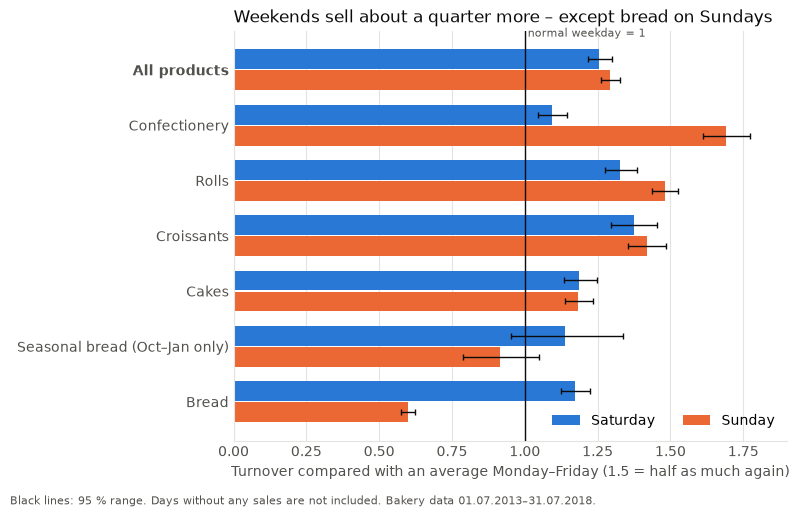

In [12]:
SAT_COLOR, SUN_COLOR = "#2a78d6", "#eb6834"
order = (ratios[ratios["day"] == "Sunday"].set_index("product_group")["ratio"]
         .drop("All products").sort_values().index.tolist()) + ["All products"]
labels = {g: g + (" (Oct–Jan only)" if g == "Seasonal bread" else "") for g in order}

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(order))
for offset, day, color in [(0.19, "Saturday", SAT_COLOR), (-0.19, "Sunday", SUN_COLOR)]:
    r = ratios[ratios["day"] == day].set_index("product_group").loc[order]
    ax.barh(y + offset, r["ratio"], height=0.36, color=color, label=day, zorder=2)
    ax.errorbar(r["ratio"], y + offset, xerr=[r["ratio"] - r["low"], r["high"] - r["ratio"]],
                fmt="none", ecolor=TEXT, elinewidth=1, capsize=2, zorder=3)
ax.axvline(1, color=TEXT, linewidth=1, zorder=4)
ax.text(1.01, len(order) - 0.45, "normal weekday = 1", fontsize=8, color=TEXT_SECONDARY, va="bottom")
ax.set_yticks(y, [labels[g] for g in order])
ax.get_yticklabels()[-1].set_fontweight("bold")
ax.set_xlabel("Turnover compared with an average Monday–Friday (1.5 = half as much again)")
ax.set_xlim(0, 1.9)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.tick_params(length=0)
ax.legend(loc="lower right", frameon=False, ncols=2)
ax.set_title("Weekends sell about a quarter more – except bread on Sundays", loc="left", fontsize=12)
fig.text(0.01, -0.02, "Black lines: 95 % range. Days without any sales are not included. "
         "Bakery data 01.07.2013–31.07.2018.", fontsize=8, color=TEXT_SECONDARY)
fig.tight_layout()
fig.savefig("week-02-weekdays.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## Answer

- **All products:** Saturday (≈ 1,235) and Sunday (≈ 1,272) have clearly higher average turnover than Monday
  to Friday (≈ 957–1,008); the confidence intervals do not overlap.
- **Weekend vs. weekday (step 9):** a weekend day sells about 1.27 times an average weekday, and 96 % of all
  Saturdays and Sundays sold more than the average weekday of the same week.
- **Rolls, Croissants and Cakes** follow the same pattern: the weekend is highest.
- **Bread** is the exception: lowest on Sunday (≈ 76 versus ≈ 117–148 on the other days).
- **Confectionery** peaks on Sunday (≈ 134 versus ≈ 77–86).
- **Seasonal bread** (only 292 days) shows no clear weekday pattern; its intervals are wide.

**Limits:** the intervals assume that days are independent. Neighbouring days are similar (season, trend,
holidays), so the real uncertainty is somewhat larger. Days without any sales are not included.